# ShopSphere Repurchase Prediction: Deep Learning with TabNet
**Course:** IT2226 AI Innovation and Deep Learning Project
**Wish-list item addressed:** W1 (*know which customers are likely to purchase in the next 30 days*), with groundwork for W2 (*why*) via TabNet's attention masks.
**Target:** `target = 1` if the customer made at least one purchase between 1 and 30 October 2024 (data cut-off: 30 September 2024).
**Database:** `shopsphere.db` (cleaned relational SQLite version of the data pack).
**Baseline:** `02_lightgbm_training_pipeline.ipynb` (LightGBM, OOF ROC-AUC 0.873 / PR-AUC 0.567 with 5-fold CV).

### Why TabNet?
TabNet (Arik & Pfister, 2021) is a deep learning architecture designed for tabular data. At each of several *decision steps* an **attentive transformer** learns a sparse mask that selects which features to look at, and a **feature transformer** processes the selected features. Two things make it a good fit here:
1. It is a genuine supervised deep network (trained end-to-end by gradient descent), satisfying project requirement 1.
2. Its feature masks give **instance-level explanations** (which features drove *this* customer's score), which supports W2 and the agent later on.

### Evaluation design (80/20)
| Split | Share of the 64,000 labelled customers | Used for |
|---|---|---|
| **Train** | 72% (90% of the 80%) | fitting model weights and preprocessing statistics |
| **Validation** | 8% (10% of the 80%) | early stopping, hyperparameter choice, decision threshold |
| **Test (hold-out)** | **20%** | **final, one-time evaluation of TabNet *and* LightGBM** |

The 80/20 split is stratified on the target. The validation set is carved out of the 80% so that **nothing about the 20% test set influences any modelling decision** (no early stopping, no threshold tuning, no model selection on test). To make the comparison fair, the LightGBM baseline is **re-trained on exactly the same split, features and validation set** (its 5-fold CV score in notebook 02 is not directly comparable to a single hold-out score).

## 1. Environment setup

In [1]:
# Install required packages (uncomment on Colab / a fresh environment)
# !pip install pytorch-tabnet lightgbm scikit-learn matplotlib seaborn pyarrow joblib -q

import os, time, json, random, warnings
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import torch
import lightgbm as lgb
from pytorch_tabnet.tab_model import TabNetClassifier
from pytorch_tabnet.pretraining import TabNetPretrainer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, accuracy_score,
                             precision_score, recall_score, classification_report, confusion_matrix,
                             roc_curve, precision_recall_curve, brier_score_loss)
from sklearn.calibration import calibration_curve

warnings.filterwarnings('ignore', category=UserWarning)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed()

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DB_PATH = 'shopsphere.db'
CUTOFF = '2024-09-30'
os.makedirs('models', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

assert os.path.exists(DB_PATH), 'shopsphere.db not found - place it next to this notebook.'
print(f'torch {torch.__version__} | device: {DEVICE} | lightgbm {lgb.__version__}')
print(f'Database: {DB_PATH} ({os.path.getsize(DB_PATH)/1024**2:.1f} MB)')

torch 2.15.0+cpu | device: cpu | lightgbm 4.7.0
Database: shopsphere.db (246.3 MB)


## 2. Customer-360 feature extraction (same SQL as the baseline)
To keep the comparison fair, we use **exactly the same feature query** as the LightGBM baseline. Child tables (transactions, sessions, deliveries, support tickets, retention contacts) are aggregated to one row per customer inside SQLite, so there is no row explosion when joining. Every time window is anchored at the cut-off date (30 Sep 2024), so no October information leaks into the features (the baseline notebook's check *B* confirmed that no late-September retention contact encodes an October purchase).

The database is opened **read-only** so the data pack cannot be altered.

In [2]:
t0 = time.time()
conn = sqlite3.connect(f'file:{DB_PATH}?mode=ro', uri=True)

feature_query = '''
WITH cust_rfm AS (
    SELECT
        customer_id,
        COUNT(transaction_id) AS total_orders,
        COALESCE(SUM(order_value), 0.0) AS total_spend_usd,
        COALESCE(AVG(order_value), 0.0) AS avg_order_value,
        COALESCE(MAX(order_value), 0.0) AS max_order_value,
        COALESCE(SUM(items_count), 0) AS total_items_bought,
        COALESCE(SUM(discount_applied), 0) AS discounted_orders_count,
        COALESCE(SUM(high_value_flag), 0) AS high_value_orders_count,
        COALESCE(SUM(CASE WHEN transaction_timestamp >= '2024-09-01' THEN 1 ELSE 0 END), 0) AS orders_last_30d,
        COALESCE(SUM(CASE WHEN transaction_timestamp >= '2024-07-01' THEN 1 ELSE 0 END), 0) AS orders_last_90d,
        ROUND(JULIANDAY('2024-09-30') - JULIANDAY(MAX(transaction_timestamp)), 1) AS recency_days
    FROM transactions
    GROUP BY customer_id
),
cust_sessions AS (
    SELECT
        customer_id,
        COUNT(session_id) AS total_sessions,
        COALESCE(SUM(pages_viewed), 0) AS total_pages_viewed,
        COALESCE(SUM(cart_additions), 0) AS total_cart_additions,
        COALESCE(SUM(bounce_flag), 0) AS total_bounced_sessions,
        COALESCE(AVG(session_duration_capped), 0.0) AS avg_session_duration_s,
        COALESCE(SUM(CASE WHEN session_timestamp >= '2024-09-01' THEN 1 ELSE 0 END), 0) AS sessions_last_30d,
        COALESCE(SUM(CASE WHEN session_timestamp >= '2024-07-01' THEN 1 ELSE 0 END), 0) AS sessions_last_90d,
        ROUND(JULIANDAY('2024-09-30') - JULIANDAY(MAX(session_timestamp)), 1) AS days_since_last_session
    FROM sessions
    GROUP BY customer_id
),
cust_deliveries AS (
    SELECT
        t.customer_id,
        COUNT(d.transaction_id) AS total_deliveries,
        COALESCE(SUM(CASE WHEN d.delivery_status = 'Delivered Late' THEN 1 ELSE 0 END), 0) AS late_deliveries_count,
        COALESCE(SUM(CASE WHEN d.delivery_status = 'Lost' THEN 1 ELSE 0 END), 0) AS lost_packages_count,
        COALESCE(AVG(d.delay_days), 0.0) AS avg_delay_days
    FROM transactions t
    JOIN deliveries d ON t.transaction_id = d.transaction_id
    GROUP BY t.customer_id
),
cust_tickets AS (
    SELECT
        customer_id,
        COUNT(ticket_id) AS total_support_tickets,
        COALESCE(SUM(CASE WHEN status = 'Open' THEN 1 ELSE 0 END), 0) AS open_tickets_count,
        COALESCE(SUM(CASE WHEN status = 'Open' AND priority IN ('High', 'Urgent') THEN 1 ELSE 0 END), 0) AS high_priority_open_tickets,
        AVG(csat_score) AS avg_csat_score
    FROM support_tickets
    GROUP BY customer_id
),
cust_retention AS (
    SELECT
        customer_id,
        COUNT(contact_id) AS retention_contacts_count,
        COALESCE(SUM(redeemed), 0) AS retention_redeemed_count,
        COALESCE(SUM(purchased_within_14d), 0) AS retention_purchased_count
    FROM retention_contact_history
    GROUP BY customer_id
)
SELECT
    c.customer_id,
    c.age,
    c.age_is_missing,
    c.country_code,
    c.customer_tier,
    c.credit_limit,
    c.loyalty_score,
    c.email_open_rate,
    c.email_open_rate_is_missing,
    c.avg_review_score,
    ROUND(JULIANDAY('2024-09-30') - JULIANDAY(c.signup_date), 1) AS account_age_days,
    COALESCE(p.email_opt_in, 0) AS email_opt_in,
    COALESCE(p.sms_opt_in, 0) AS sms_opt_in,
    COALESCE(p.do_not_contact, 0) AS do_not_contact,
    COALESCE(p.preferred_channel, 'unknown') AS preferred_channel,
    COALESCE(rfm.total_orders, 0) AS total_orders,
    COALESCE(rfm.total_spend_usd, 0.0) AS total_spend_usd,
    COALESCE(rfm.avg_order_value, 0.0) AS avg_order_value,
    COALESCE(rfm.max_order_value, 0.0) AS max_order_value,
    COALESCE(rfm.total_items_bought, 0) AS total_items_bought,
    COALESCE(rfm.discounted_orders_count, 0) AS discounted_orders_count,
    COALESCE(rfm.high_value_orders_count, 0) AS high_value_orders_count,
    COALESCE(rfm.orders_last_30d, 0) AS orders_last_30d,
    COALESCE(rfm.orders_last_90d, 0) AS orders_last_90d,
    rfm.recency_days,
    COALESCE(s.total_sessions, 0) AS total_sessions,
    COALESCE(s.total_pages_viewed, 0) AS total_pages_viewed,
    COALESCE(s.total_cart_additions, 0) AS total_cart_additions,
    COALESCE(s.total_bounced_sessions, 0) AS total_bounced_sessions,
    COALESCE(s.avg_session_duration_s, 0.0) AS avg_session_duration_s,
    COALESCE(s.sessions_last_30d, 0) AS sessions_last_30d,
    COALESCE(s.sessions_last_90d, 0) AS sessions_last_90d,
    s.days_since_last_session,
    COALESCE(d.total_deliveries, 0) AS total_deliveries,
    COALESCE(d.late_deliveries_count, 0) AS late_deliveries_count,
    COALESCE(d.lost_packages_count, 0) AS lost_packages_count,
    COALESCE(d.avg_delay_days, 0.0) AS avg_delay_days,
    COALESCE(t.total_support_tickets, 0) AS total_support_tickets,
    COALESCE(t.open_tickets_count, 0) AS open_tickets_count,
    COALESCE(t.high_priority_open_tickets, 0) AS high_priority_open_tickets,
    t.avg_csat_score,
    COALESCE(r.retention_contacts_count, 0) AS retention_contacts_count,
    COALESCE(r.retention_redeemed_count, 0) AS retention_redeemed_count,
    COALESCE(r.retention_purchased_count, 0) AS retention_purchased_count,
    tr.target,
    CASE WHEN te.customer_id IS NOT NULL THEN 1 ELSE 0 END AS is_test
FROM customers c
LEFT JOIN customer_preferences p ON c.customer_id = p.customer_id
LEFT JOIN cust_rfm rfm ON c.customer_id = rfm.customer_id
LEFT JOIN cust_sessions s ON c.customer_id = s.customer_id
LEFT JOIN cust_deliveries d ON c.customer_id = d.customer_id
LEFT JOIN cust_tickets t ON c.customer_id = t.customer_id
LEFT JOIN cust_retention r ON c.customer_id = r.customer_id
LEFT JOIN train tr ON c.customer_id = tr.customer_id
LEFT JOIN test te ON c.customer_id = te.customer_id;
'''

df = pd.read_sql_query(feature_query, conn)
conn.close()
print(f'Extracted {len(df):,} customers x {df.shape[1]} columns in {time.time()-t0:.1f}s')
df.head()

Extracted 80,000 customers x 46 columns in 30.1s


,customer_id,age,age_is_missing,country_code,customer_tier,credit_limit,loyalty_score,email_open_rate,email_open_rate_is_missing,avg_review_score,...,avg_delay_days,total_support_tickets,open_tickets_count,high_priority_open_tickets,avg_csat_score,retention_contacts_count,retention_redeemed_count,retention_purchased_count,target,is_test
0,0,51.0,0,DE,Bronze,17757.0,0.248,0.234475,0,4.21,...,0.0,0,0,0,NaN,1,0,0,0.0,0
1,1,39.0,0,US,Bronze,3424.0,0.077,0.610079,0,3.87,...,0.0,0,0,0,NaN,0,0,0,0.0,0
2,2,56.0,0,UK,Bronze,13373.0,0.160,0.466131,0,4.74,...,0.0,0,0,0,NaN,1,0,0,NaN,1
3,3,29.0,0,UK,Silver,18995.0,0.163,0.482747,0,4.07,...,0.0,0,0,0,NaN,0,0,0,NaN,1
4,4,44.0,0,FR,Bronze,11074.0,0.133,0.206030,0,3.34,...,0.0,1,0,0,NaN,0,0,0,0.0,0


## 3. Behavioural feature engineering
Same derived ratios as the baseline: discount reliance, bounce rate, cart abandonment and a 90-day inactivity flag.

In [3]:
df['discount_order_ratio'] = np.where(df['total_orders'] > 0, df['discounted_orders_count'] / df['total_orders'].clip(lower=1), 0.0)
df['bounce_rate'] = np.where(df['total_sessions'] > 0, df['total_bounced_sessions'] / df['total_sessions'].clip(lower=1), 0.0)
df['cart_abandonment_ratio'] = np.where(
    df['total_cart_additions'] > 0,
    np.clip(1.0 - df['total_orders'] / df['total_cart_additions'].clip(lower=1), 0.0, 1.0), 0.0)
df['is_inactive_90d'] = ((df['orders_last_90d'] == 0) & (df['sessions_last_90d'] == 0)).astype(int)

CATEGORICAL_COLS = ['country_code', 'customer_tier', 'preferred_channel']
EXCLUDE_COLS = ['customer_id', 'target', 'is_test']
FEATURE_COLS = [c for c in df.columns if c not in EXCLUDE_COLS]
NUMERIC_COLS = [c for c in FEATURE_COLS if c not in CATEGORICAL_COLS]

labelled = df[df['is_test'] == 0].reset_index(drop=True)
unlabelled = df[df['is_test'] == 1].reset_index(drop=True)   # test.csv customers (no labels)
y_all = labelled['target'].astype(int).values

print(f'Features: {len(FEATURE_COLS)} ({len(NUMERIC_COLS)} numeric, {len(CATEGORICAL_COLS)} categorical)')
print(f'Labelled customers: {len(labelled):,} | positive rate {y_all.mean():.2%}')
print(f'Unlabelled (test.csv) customers: {len(unlabelled):,}')

Features: 47 (44 numeric, 3 categorical)
Labelled customers: 64,000 | positive rate 14.57%
Unlabelled (test.csv) customers: 16,000


### 3.1 Quick data checks relevant to a neural network
Tree models handle missing values and heavy-tailed counts natively, **neural networks do not**: TabNet needs every input to be a finite number, and gradient descent behaves best when inputs are on similar scales. The checks below drive the preprocessing in Section 5.

Share of missing values (labelled set):
avg_csat_score             85.6%
recency_days               38.5%
email_open_rate            18.2%
days_since_last_session     8.1%
age                         5.2%

Most right-skewed numeric features:
high_priority_open_tickets    44.7
avg_session_duration_s        19.4
bounce_rate                   16.0
open_tickets_count            14.9
retention_redeemed_count      12.3
high_value_orders_count        9.5
retention_purchased_count      9.1
lost_packages_count            8.1
total_spend_usd                7.3
do_not_contact                 6.9


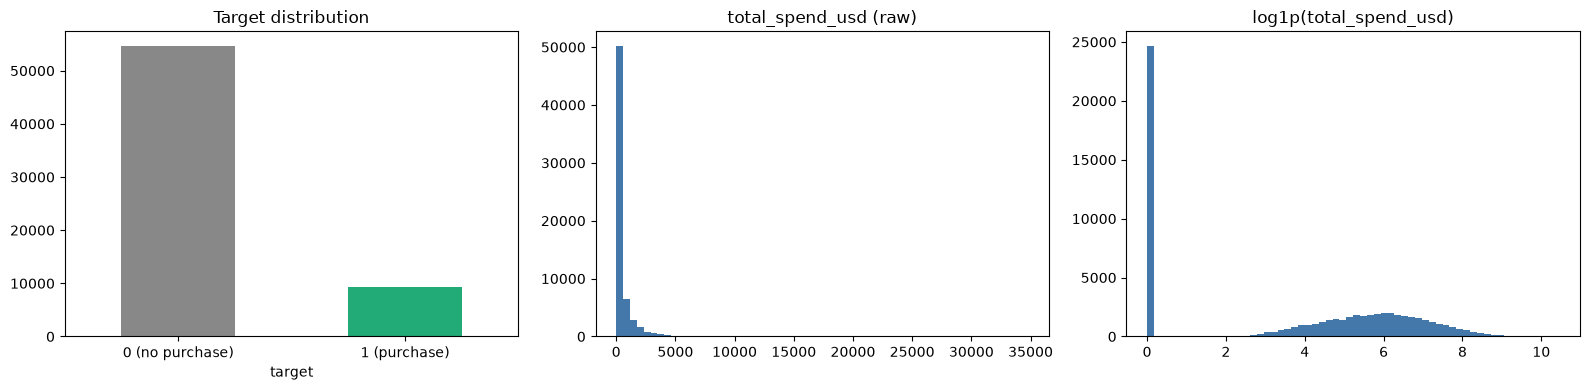

In [4]:
na = labelled[FEATURE_COLS].isna().mean().loc[lambda s: s > 0].sort_values(ascending=False)
print('Share of missing values (labelled set):')
print(na.map('{:.1%}'.format).to_string())

skew = labelled[NUMERIC_COLS].skew().sort_values(ascending=False)
print('\nMost right-skewed numeric features:')
print(skew.head(10).round(1).to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
labelled['target'].value_counts().sort_index().plot.bar(ax=axes[0], color=['#888', '#2a7'])
axes[0].set_title('Target distribution'); axes[0].set_xticklabels(['0 (no purchase)', '1 (purchase)'], rotation=0)
axes[1].hist(labelled['total_spend_usd'], bins=60, color='#47a'); axes[1].set_title('total_spend_usd (raw)')
axes[2].hist(np.log1p(labelled['total_spend_usd']), bins=60, color='#47a'); axes[2].set_title('log1p(total_spend_usd)')
plt.tight_layout(); plt.show()

**Findings.** (i) The target is imbalanced (~14.6% positives), so accuracy alone is misleading: predicting *"nobody buys"* already scores ~85% accuracy. We therefore use **ROC-AUC** (ranking quality) and **PR-AUC** (precision/recall on the minority class) as primary metrics, and F1 at a tuned threshold as the operating metric. (ii) Missingness is *informative*: `recency_days` is NaN for customers who never ordered, `days_since_last_session` for customers who never visited, `avg_csat_score` for customers with no tickets. Simply imputing would erase that signal, so we add explicit `_isna` indicator columns. (iii) Many count/monetary features are heavily right-skewed; a `log1p` transform followed by standardisation makes them better behaved for gradient descent.

## 4. Stratified 80/20 train/test split

In [5]:
idx_all = np.arange(len(labelled))
# 80% train+validation / 20% hold-out test (stratified on target)
idx_trval, idx_test = train_test_split(idx_all, test_size=0.20, stratify=y_all, random_state=SEED)
# validation = 10% of the 80% portion, used only for early stopping, tuning and thresholding
idx_train, idx_val = train_test_split(idx_trval, test_size=0.10, stratify=y_all[idx_trval], random_state=SEED)

y_train, y_val, y_test = y_all[idx_train], y_all[idx_val], y_all[idx_test]
split_summary = pd.DataFrame({
    'rows': [len(idx_train), len(idx_val), len(idx_test)],
    'share_of_labelled': [len(idx_train)/len(idx_all), len(idx_val)/len(idx_all), len(idx_test)/len(idx_all)],
    'positive_rate': [y_train.mean(), y_val.mean(), y_test.mean()]},
    index=['train', 'validation', 'test (hold-out)'])
display(split_summary.style.format({'share_of_labelled': '{:.1%}', 'positive_rate': '{:.2%}'}))

assert not set(idx_test) & set(idx_trval), 'test rows leaked into train/val'
assert abs(len(idx_test) / len(idx_all) - 0.20) < 1e-3
pd.DataFrame({'customer_id': labelled.loc[idx_test, 'customer_id']}).to_csv('outputs/test_split_customer_ids.csv', index=False)

,rows,share_of_labelled,positive_rate
train,46080,72.0%,14.57%
validation,5120,8.0%,14.57%
test (hold-out),12800,20.0%,14.57%


## 5. Preprocessing pipeline for TabNet
All statistics (medians, category vocabularies, scaler means/stds, which columns to log-transform) are **learned on the training split only** and then applied unchanged to validation, test and new customers. This avoids the classic leakage mistake of scaling with statistics computed on the full dataset.

| Step | Why |
|---|---|
| `_isna` indicator columns | keep the information *"never ordered / never visited / never raised a ticket"* |
| median imputation | TabNet cannot accept NaN |
| `log1p` on non-negative, heavily skewed columns (skew > 2) | compress long tails such as spend and session counts |
| standard scaling | puts features on a comparable scale for gradient descent |
| integer-encoding of categoricals (0 = unseen) | TabNet learns an **embedding** for each categorical instead of a one-hot vector |

In [6]:
# The class lives in tabnet_preprocessing.py so the fitted object can be unpickled outside this notebook
# (by the agent / dashboard). Open that file to see the full implementation.
from tabnet_preprocessing import TabNetPreprocessor
import inspect; print(inspect.getsource(TabNetPreprocessor))

prep = TabNetPreprocessor(NUMERIC_COLS, CATEGORICAL_COLS).fit(labelled.iloc[idx_train])
X_train = prep.transform(labelled.iloc[idx_train])
X_val   = prep.transform(labelled.iloc[idx_val])
X_test  = prep.transform(labelled.iloc[idx_test])

print(f'TabNet input width: {X_train.shape[1]} columns')
print(f'log1p-transformed columns ({len(prep.log_cols_)}): {prep.log_cols_}')
print(f'missing-indicator columns: {[c + "_isna" for c in prep.nan_cols_]}')
print(f'categorical embeddings: {dict(zip(CATEGORICAL_COLS, prep.cat_dims_))}')
assert np.isfinite(X_train).all() and np.isfinite(X_val).all() and np.isfinite(X_test).all()

class TabNetPreprocessor:
    """Fit-on-train / transform-anywhere preprocessing for TabNet.

    fit(): learns medians, which columns to log1p, category vocabularies and scaler on the TRAIN split only.
    transform(): adds _isna indicators, imputes, log-transforms, scales and integer-encodes categoricals (0 = unseen).
    """
    def __init__(self, numeric_cols, categorical_cols, skew_threshold=2.0):
        self.numeric_cols, self.categorical_cols, self.skew_threshold = list(numeric_cols), list(categorical_cols), skew_threshold

    def fit(self, data):
        num = data[self.numeric_cols]
        self.nan_cols_ = [c for c in self.numeric_cols if num[c].isna().any()]
        self.medians_ = num.median()
        self.log_cols_ = [c for c in self.numeric_cols
                          if num[c].min() >= 0 and num[c].skew() > self.skew_threshold]
        self.vocab_ = {c: sorted(data[c].astype(str).unique()) for c in self.categorical_cols}
        self.scaler_ = StandardScaler().fit(s

## 6. Non-deep-learning baseline: LightGBM on the same split
Same hyper-parameters as notebook 02, same 47 features, trained on the **same 72% train split** with early stopping on the **same validation split**, and scored once on the **same 20% test split**.

In [7]:
X_lgb = labelled[FEATURE_COLS].copy()
for c in CATEGORICAL_COLS:
    X_lgb[c] = X_lgb[c].astype('category')

lgb_params = {
    'objective': 'binary', 'metric': 'auc', 'boosting_type': 'gbdt', 'learning_rate': 0.03,
    'num_leaves': 31, 'max_depth': -1, 'min_child_samples': 30, 'subsample': 0.8, 'colsample_bytree': 0.8,
    'scale_pos_weight': (y_train == 0).sum() / y_train.sum(), 'random_state': SEED, 'n_jobs': -1, 'verbose': -1}

t0 = time.time()
lgb_model = lgb.train(
    lgb_params,
    lgb.Dataset(X_lgb.iloc[idx_train], label=y_train, categorical_feature=CATEGORICAL_COLS),
    num_boost_round=1200,
    valid_sets=[lgb.Dataset(X_lgb.iloc[idx_val], label=y_val, categorical_feature=CATEGORICAL_COLS)],
    callbacks=[lgb.early_stopping(50, verbose=False)])
lgb_val_proba = lgb_model.predict(X_lgb.iloc[idx_val], num_iteration=lgb_model.best_iteration)
lgb_test_proba = lgb_model.predict(X_lgb.iloc[idx_test], num_iteration=lgb_model.best_iteration)
print(f'LightGBM trained in {time.time()-t0:.1f}s | best iteration {lgb_model.best_iteration}')
print(f'Validation ROC-AUC {roc_auc_score(y_val, lgb_val_proba):.4f}')

LightGBM trained in 3.0s | best iteration 166
Validation ROC-AUC 0.8733


## 7. TabNet hyper-parameter search (on the validation split)
Key TabNet hyper-parameters:
* `n_d`, `n_a` - width of the decision and attention layers (model capacity).
* `n_steps` - number of sequential decision steps (each step attends to a different subset of features).
* `gamma` - feature re-use penalty; higher values force different steps to use different features.
* `lambda_sparse` - strength of the sparsity regulariser on the attention masks (sparser = more interpretable).
* `weights` - `0` = natural class frequencies, `1` = oversample positives so each batch is balanced (the deep-learning analogue of `scale_pos_weight`).

Each configuration is trained with Adam, a step learning-rate decay, **ghost batch normalisation** (`virtual_batch_size`), and early stopping on validation ROC-AUC (patience 12 epochs). Selection is by **validation** ROC-AUC only.

In [8]:
COMMON = dict(cat_idxs=prep.cat_idxs_, cat_dims=prep.cat_dims_, cat_emb_dim=3,
              optimizer_fn=torch.optim.Adam,
              scheduler_fn=torch.optim.lr_scheduler.StepLR, scheduler_params=dict(step_size=10, gamma=0.8),
              mask_type='sparsemax', seed=SEED, verbose=0, device_name=DEVICE)
FIT = dict(eval_metric=['auc'], max_epochs=120, patience=12, batch_size=1024, virtual_batch_size=128, drop_last=False)

search_space = [
    dict(n_d=8,  n_a=8,  n_steps=3, gamma=1.3, lambda_sparse=1e-3, lr=2e-2, weights=0),
    dict(n_d=16, n_a=16, n_steps=3, gamma=1.3, lambda_sparse=1e-4, lr=2e-2, weights=0),
    dict(n_d=16, n_a=16, n_steps=3, gamma=1.3, lambda_sparse=1e-4, lr=2e-2, weights=1),
    dict(n_d=16, n_a=16, n_steps=4, gamma=1.5, lambda_sparse=1e-4, lr=1e-2, weights=0),
    dict(n_d=24, n_a=24, n_steps=3, gamma=1.3, lambda_sparse=1e-4, lr=1e-2, weights=0),
    dict(n_d=32, n_a=32, n_steps=5, gamma=1.5, lambda_sparse=1e-4, lr=2e-2, weights=0),
]

def make_tabnet(cfg):
    return TabNetClassifier(n_d=cfg['n_d'], n_a=cfg['n_a'], n_steps=cfg['n_steps'], gamma=cfg['gamma'],
                            lambda_sparse=cfg['lambda_sparse'], optimizer_params=dict(lr=cfg['lr']), **COMMON)

# monitor training AUC on a 10k random subsample of the train split (saves time per epoch)
trn_mon = np.random.RandomState(SEED).choice(len(X_train), 10000, replace=False)
results, models = [], {}
for i, cfg in enumerate(search_space):
    set_seed(); t0 = time.time()
    clf = make_tabnet(cfg)
    clf.fit(X_train, y_train, eval_set=[(X_train[trn_mon], y_train[trn_mon]), (X_val, y_val)], eval_name=['train', 'val'],
            weights=cfg['weights'], **FIT)
    val_auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:, 1])
    results.append({**cfg, 'best_epoch': clf.best_epoch, 'val_auc': val_auc, 'train_auc_at_best': clf.history['train_auc'][clf.best_epoch],
                    'minutes': (time.time() - t0) / 60})
    models[i] = clf
    print(f"[{i}] {cfg} -> val AUC {val_auc:.4f} (best epoch {clf.best_epoch}, {results[-1]['minutes']:.1f} min)")

search_df = pd.DataFrame(results).sort_values('val_auc', ascending=False)
search_df.to_csv('outputs/tabnet_hparam_search.csv', index=False)
display(search_df.style.format({'val_auc': '{:.4f}', 'train_auc_at_best': '{:.4f}', 'minutes': '{:.1f}', 'lambda_sparse': '{:.0e}'}))
best_idx = int(search_df.index[0]); best_cfg = search_space[best_idx]
print('Best configuration (by validation ROC-AUC):', best_cfg)


Early stopping occurred at epoch 47 with best_epoch = 35 and best_val_auc = 0.87501
[0] {'n_d': 8, 'n_a': 8, 'n_steps': 3, 'gamma': 1.3, 'lambda_sparse': 0.001, 'lr': 0.02, 'weights': 0} -> val AUC 0.8750 (best epoch 35, 1.8 min)

Early stopping occurred at epoch 49 with best_epoch = 37 and best_val_auc = 0.8703
[1] {'n_d': 16, 'n_a': 16, 'n_steps': 3, 'gamma': 1.3, 'lambda_sparse': 0.0001, 'lr': 0.02, 'weights': 0} -> val AUC 0.8703 (best epoch 37, 1.9 min)

Early stopping occurred at epoch 16 with best_epoch = 4 and best_val_auc = 0.86854
[2] {'n_d': 16, 'n_a': 16, 'n_steps': 3, 'gamma': 1.3, 'lambda_sparse': 0.0001, 'lr': 0.02, 'weights': 1} -> val AUC 0.8685 (best epoch 4, 0.8 min)

Early stopping occurred at epoch 57 with best_epoch = 45 and best_val_auc = 0.86435
[3] {'n_d': 16, 'n_a': 16, 'n_steps': 4, 'gamma': 1.5, 'lambda_sparse': 0.0001, 'lr': 0.01, 'weights': 0} -> val AUC 0.8644 (best epoch 45, 3.4 min)

Early stopping occurred at epoch 32 with best_epoch = 20 and best_val

,n_d,n_a,n_steps,gamma,lambda_sparse,lr,weights,best_epoch,val_auc,train_auc_at_best,minutes
0,8,8,3,1.300000,1e-03,0.020000,0,35,0.8750,0.8813,1.8
1,16,16,3,1.300000,1e-04,0.020000,0,37,0.8703,0.8838,1.9
2,16,16,3,1.300000,1e-04,0.020000,1,4,0.8685,0.8767,0.8
5,32,32,5,1.500000,1e-04,0.020000,0,32,0.8685,0.8746,4.1
4,24,24,3,1.300000,1e-04,0.010000,0,20,0.8684,0.8781,1.7
3,16,16,4,1.500000,1e-04,0.010000,0,45,0.8644,0.8707,3.4


Best configuration (by validation ROC-AUC): {'n_d': 8, 'n_a': 8, 'n_steps': 3, 'gamma': 1.3, 'lambda_sparse': 0.001, 'lr': 0.02, 'weights': 0}


## 8. Optimisation: self-supervised pre-training
TabNet supports **self-supervised pre-training**: an encoder-decoder learns to reconstruct randomly masked input features, so it learns the structure of the data before seeing any labels. The encoder weights then initialise the classifier.

We pre-train on the **feature columns only** (no labels) of the training split plus the 16,000 unlabelled customers in `test.csv`. The 20% hold-out and the validation split are **not** used for pre-training, so they remain completely unseen. We keep pre-training only if it improves *validation* ROC-AUC.

In [9]:
X_unlab = prep.transform(unlabelled)
X_pretrain = np.vstack([X_train, X_unlab])

set_seed(); t0 = time.time()
pretrainer = TabNetPretrainer(n_d=best_cfg['n_d'], n_a=best_cfg['n_a'], n_steps=best_cfg['n_steps'],
                              gamma=best_cfg['gamma'], lambda_sparse=best_cfg['lambda_sparse'],
                              optimizer_params=dict(lr=best_cfg['lr']), **COMMON)
# The pre-trainer's validation set must be label-free: use a slice of the pre-training pool itself.
rng = np.random.RandomState(SEED); pt_val = rng.rand(len(X_pretrain)) < 0.1
pretrainer.fit(X_pretrain[~pt_val], eval_set=[X_pretrain[pt_val]], pretraining_ratio=0.5,
               max_epochs=60, patience=8, batch_size=1024, virtual_batch_size=128)
print(f'Pre-training finished in {(time.time()-t0)/60:.1f} min (best epoch {pretrainer.best_epoch})')

set_seed(); t0 = time.time()
clf_pt = make_tabnet(best_cfg)
clf_pt.fit(X_train, y_train, eval_set=[(X_train[trn_mon], y_train[trn_mon]), (X_val, y_val)], eval_name=['train', 'val'],
           weights=best_cfg['weights'], from_unsupervised=pretrainer, **FIT)
val_auc_pt = roc_auc_score(y_val, clf_pt.predict_proba(X_val)[:, 1])
val_auc_best = search_df.iloc[0]['val_auc']
print(f'Fine-tuning finished in {(time.time()-t0)/60:.1f} min')
print(f'Validation ROC-AUC  without pre-training: {val_auc_best:.4f} | with pre-training: {val_auc_pt:.4f}')

USE_PRETRAINING = val_auc_pt > val_auc_best
tabnet = clf_pt if USE_PRETRAINING else models[best_idx]
print('Selected final TabNet:', 'pre-trained + fine-tuned' if USE_PRETRAINING else 'trained from scratch')


Early stopping occurred at epoch 8 with best_epoch = 0 and best_val_0_unsup_loss_numpy = 6.829800128936768
Pre-training finished in 0.5 min (best epoch 0)

Early stopping occurred at epoch 39 with best_epoch = 27 and best_val_auc = 0.87334
Fine-tuning finished in 1.8 min
Validation ROC-AUC  without pre-training: 0.8750 | with pre-training: 0.8733
Selected final TabNet: trained from scratch


## 9. Training curves of the selected TabNet
A widening gap between training and validation AUC indicates over-fitting; early stopping restores the weights from the best validation epoch.

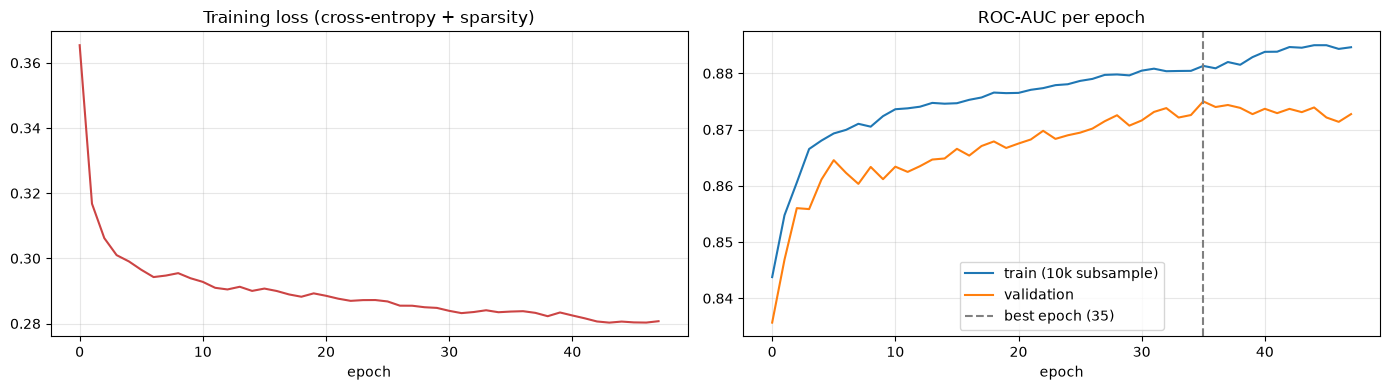

In [10]:
h = tabnet.history
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(h['loss'], color='#c44'); axes[0].set_title('Training loss (cross-entropy + sparsity)'); axes[0].set_xlabel('epoch')
axes[1].plot(h['train_auc'], label='train (10k subsample)'); axes[1].plot(h['val_auc'], label='validation')
axes[1].axvline(tabnet.best_epoch, ls='--', c='grey', label=f'best epoch ({tabnet.best_epoch})')
axes[1].set_title('ROC-AUC per epoch'); axes[1].set_xlabel('epoch'); axes[1].legend()
for a in axes: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 10. Decision threshold (chosen on validation, not test)
The model outputs a probability. Staff need a yes/no list, so we need a threshold. As in the baseline we choose the threshold that maximises F1, but **on the validation split** - picking it on the test set would inflate the test F1. The same procedure is applied to LightGBM.

In [11]:
tabnet_val_proba = tabnet.predict_proba(X_val)[:, 1]
tabnet_test_proba = tabnet.predict_proba(X_test)[:, 1]

def best_f1_threshold(y_true, proba):
    grid = np.arange(0.05, 0.96, 0.01)
    scores = [f1_score(y_true, (proba >= t).astype(int)) for t in grid]
    return float(grid[int(np.argmax(scores))]), float(max(scores))

thr_tabnet, f1v_tabnet = best_f1_threshold(y_val, tabnet_val_proba)
thr_lgb, f1v_lgb = best_f1_threshold(y_val, lgb_val_proba)
print(f'TabNet   threshold {thr_tabnet:.2f} (validation F1 {f1v_tabnet:.4f})')
print(f'LightGBM threshold {thr_lgb:.2f} (validation F1 {f1v_lgb:.4f})')

TabNet   threshold 0.25 (validation F1 0.5392)
LightGBM threshold 0.69 (validation F1 0.5416)


## 11. Final evaluation on the 20% hold-out test set
This is the first and only time the test split is used.

In [12]:
def evaluate(name, y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    return {'model': name, 'ROC-AUC': roc_auc_score(y_true, proba), 'PR-AUC': average_precision_score(y_true, proba),
            'F1': f1_score(y_true, pred), 'Precision': precision_score(y_true, pred), 'Recall': recall_score(y_true, pred),
            'Accuracy': accuracy_score(y_true, pred), 'Brier': brier_score_loss(y_true, proba), 'Threshold': thr,
            'Predicted positive rate': pred.mean()}

majority = {'model': 'Majority class (predict nobody buys)', 'ROC-AUC': 0.5, 'PR-AUC': y_test.mean(), 'F1': 0.0,
            'Precision': 0.0, 'Recall': 0.0, 'Accuracy': 1 - y_test.mean(), 'Brier': np.nan, 'Threshold': np.nan,
            'Predicted positive rate': 0.0}
comparison = pd.DataFrame([evaluate('TabNet (deep learning)', y_test, tabnet_test_proba, thr_tabnet),
                           evaluate('LightGBM (baseline)', y_test, lgb_test_proba, thr_lgb),
                           majority]).set_index('model')
comparison.to_csv('outputs/model_comparison_test.csv')
display(comparison.style.format('{:.4f}', na_rep='-').highlight_max(subset=['ROC-AUC', 'PR-AUC', 'F1'], color='#cfe8cf'))

for name, proba, thr in [('TabNet', tabnet_test_proba, thr_tabnet), ('LightGBM', lgb_test_proba, thr_lgb)]:
    print(f'\n{name} - classification report on the 20% test split (threshold {thr:.2f})')
    print(classification_report(y_test, (proba >= thr).astype(int), digits=4, target_names=['no purchase', 'purchase']))

,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy,Brier,Threshold,Predicted positive rate
model,,,,,,,,,
TabNet (deep learning),0.8736,0.5681,0.5412,0.4719,0.6343,0.8433,0.0882,0.2500,0.1959
LightGBM (baseline),0.8756,0.5706,0.5430,0.4967,0.5989,0.8531,0.1472,0.6900,0.1757
Majority class (predict nobody buys),0.5000,0.1457,0.0000,0.0000,0.0000,0.8543,-,-,0.0000



TabNet - classification report on the 20% test split (threshold 0.25)
              precision    recall  f1-score   support

 no purchase     0.9337    0.8789    0.9055     10935
    purchase     0.4719    0.6343    0.5412      1865

    accuracy                         0.8433     12800
   macro avg     0.7028    0.7566    0.7233     12800
weighted avg     0.8664    0.8433    0.8524     12800


LightGBM - classification report on the 20% test split (threshold 0.69)
              precision    recall  f1-score   support

 no purchase     0.9291    0.8965    0.9125     10935
    purchase     0.4967    0.5989    0.5430      1865

    accuracy                         0.8531     12800
   macro avg     0.7129    0.7477    0.7278     12800
weighted avg     0.8661    0.8531    0.8587     12800



### 11.1 Is the difference real? Paired bootstrap on the test set
A single test score has sampling noise. We resample the 12,800 test customers with replacement 1,000 times, recompute both models' metrics on the **same** resample, and look at the distribution of the difference (TabNet - LightGBM). If the 95% interval contains 0, the two models are statistically indistinguishable on this data.

In [13]:
rng = np.random.RandomState(SEED)
boot = []
for _ in range(1000):
    s = rng.randint(0, len(y_test), len(y_test))
    if y_test[s].min() == y_test[s].max():
        continue
    boot.append({'d_roc': roc_auc_score(y_test[s], tabnet_test_proba[s]) - roc_auc_score(y_test[s], lgb_test_proba[s]),
                 'd_pr': average_precision_score(y_test[s], tabnet_test_proba[s]) - average_precision_score(y_test[s], lgb_test_proba[s])})
boot = pd.DataFrame(boot)
for col, label in [('d_roc', 'ROC-AUC'), ('d_pr', 'PR-AUC')]:
    lo, hi = np.percentile(boot[col], [2.5, 97.5])
    print(f'{label} difference (TabNet - LightGBM): mean {boot[col].mean():+.4f}, 95% CI [{lo:+.4f}, {hi:+.4f}]'
          f"  -> {'significant' if (lo > 0 or hi < 0) else 'not significant'}")

ROC-AUC difference (TabNet - LightGBM): mean -0.0019, 95% CI [-0.0041, +0.0003]  -> not significant
PR-AUC difference (TabNet - LightGBM): mean -0.0026, 95% CI [-0.0103, +0.0054]  -> not significant


### 11.2 ROC, precision-recall, calibration and confusion matrices

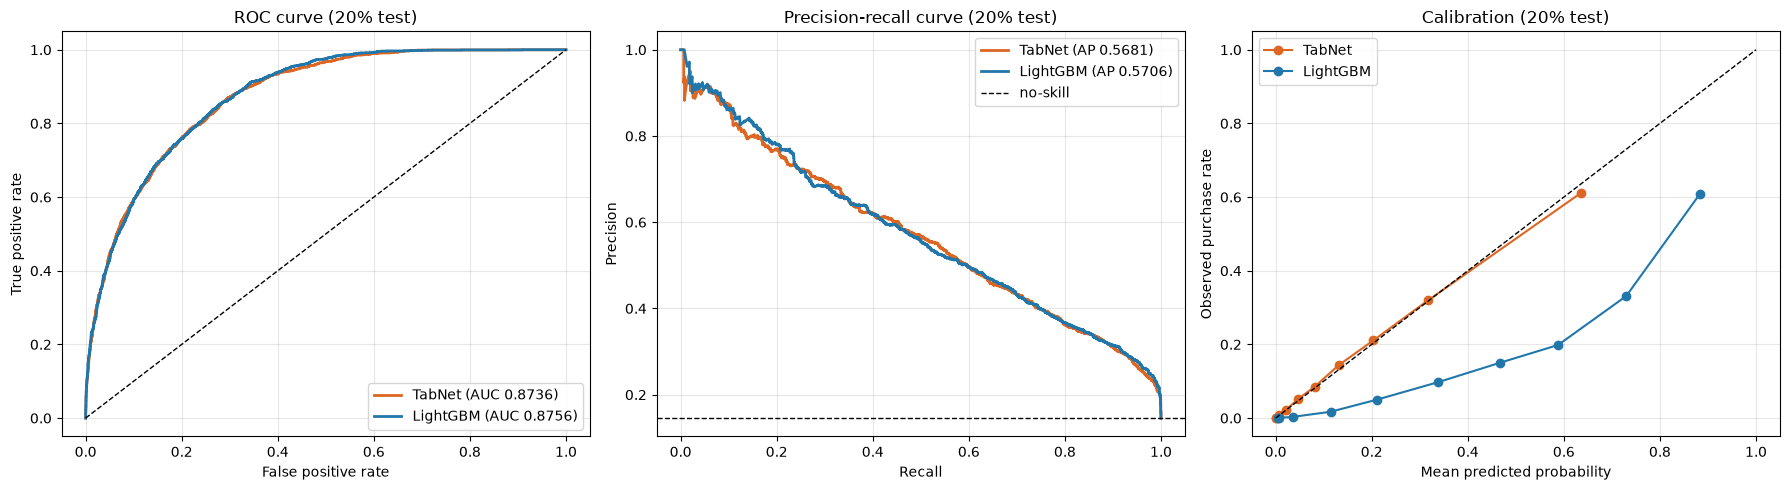

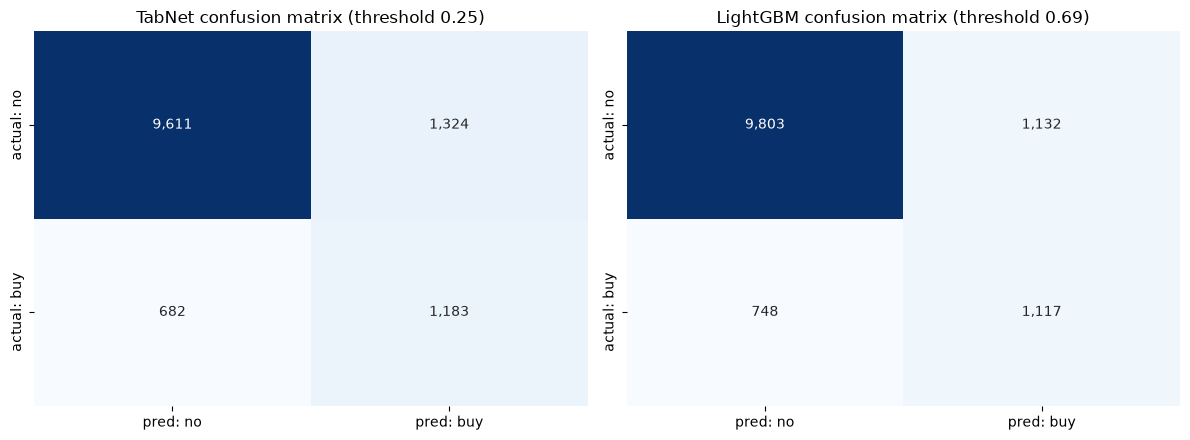

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for name, proba, color in [('TabNet', tabnet_test_proba, '#d62'), ('LightGBM', lgb_test_proba, '#27a')]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC {roc_auc_score(y_test, proba):.4f})')
    p, r, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(r, p, color=color, lw=2, label=f'{name} (AP {average_precision_score(y_test, proba):.4f})')
    frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10, strategy='quantile')
    axes[2].plot(mean_pred, frac_pos, 'o-', color=color, label=name)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1); axes[0].set(title='ROC curve (20% test)', xlabel='False positive rate', ylabel='True positive rate')
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1, label='no-skill'); axes[1].set(title='Precision-recall curve (20% test)', xlabel='Recall', ylabel='Precision')
axes[2].plot([0, 1], [0, 1], 'k--', lw=1); axes[2].set(title='Calibration (20% test)', xlabel='Mean predicted probability', ylabel='Observed purchase rate')
for a in axes: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for a, (name, proba, thr) in zip(axes, [('TabNet', tabnet_test_proba, thr_tabnet), ('LightGBM', lgb_test_proba, thr_lgb)]):
    cm = confusion_matrix(y_test, (proba >= thr).astype(int))
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=a,
                xticklabels=['pred: no', 'pred: buy'], yticklabels=['actual: no', 'actual: buy'])
    a.set_title(f'{name} confusion matrix (threshold {thr:.2f})')
plt.tight_layout(); plt.show()

### 11.3 Business view: precision in the top of the ranked list
The CRM team works from a ranked list with a limited budget, so what matters most is how many of the *top-k* scored customers really purchase (precision@k) and what share of all buyers the list captures (recall@k).

In [15]:
def at_k(y_true, proba, frac):
    k = int(len(y_true) * frac); top = np.argsort(-proba)[:k]
    return y_true[top].mean(), y_true[top].sum() / y_true.sum()
rows = []
for frac in [0.05, 0.10, 0.20, 0.30]:
    pt, rt = at_k(y_test, tabnet_test_proba, frac); pl, rl = at_k(y_test, lgb_test_proba, frac)
    rows.append({'top % of customers': f'{frac:.0%}', 'TabNet precision': pt, 'LightGBM precision': pl,
                 'TabNet recall': rt, 'LightGBM recall': rl})
display(pd.DataFrame(rows).set_index('top % of customers').style.format('{:.3f}'))
print(f'Base rate (random list precision): {y_test.mean():.3f}')

,TabNet precision,LightGBM precision,TabNet recall,LightGBM recall
top % of customers,,,,
5%,0.722,0.722,0.248,0.248
10%,0.612,0.608,0.420,0.417
20%,0.466,0.470,0.640,0.645
30%,0.381,0.379,0.784,0.781


Base rate (random list precision): 0.146


### 11.4 Fairness check: performance by country and loyalty tier
A model that works well overall can still under-serve a group. We compare ROC-AUC per segment on the test split (responsible-AI requirement 7).

In [16]:
test_frame = labelled.iloc[idx_test][['country_code', 'customer_tier']].copy()
test_frame['y'] = y_test; test_frame['tabnet'] = tabnet_test_proba; test_frame['lgb'] = lgb_test_proba
seg_rows = []
for col in ['country_code', 'customer_tier']:
    for val, g in test_frame.groupby(col):
        seg_rows.append({'segment': f'{col}={val}', 'n': len(g), 'positive rate': g['y'].mean(),
                         'TabNet ROC-AUC': roc_auc_score(g['y'], g['tabnet']), 'LightGBM ROC-AUC': roc_auc_score(g['y'], g['lgb']),
                         'TabNet flagged rate': (g['tabnet'] >= thr_tabnet).mean()})
seg_df = pd.DataFrame(seg_rows).set_index('segment')
seg_df.to_csv('outputs/segment_performance_test.csv')
display(seg_df.style.format({'n': '{:,}', 'positive rate': '{:.2%}', 'TabNet ROC-AUC': '{:.4f}',
                             'LightGBM ROC-AUC': '{:.4f}', 'TabNet flagged rate': '{:.2%}'}))

,n,positive rate,TabNet ROC-AUC,LightGBM ROC-AUC,TabNet flagged rate
segment,,,,,
country_code=DE,"2,588",13.60%,0.8703,0.8736,19.01%
country_code=FR,"1,266",13.51%,0.8828,0.8760,19.35%
country_code=IN,"1,324",13.44%,0.8818,0.8839,18.66%
country_code=UK,"2,526",15.72%,0.8727,0.8763,21.65%
country_code=US,"5,096",15.05%,0.8718,0.8740,19.15%
customer_tier=Bronze,"8,166",5.34%,0.8602,0.8658,3.49%
customer_tier=Gold,"1,374",29.77%,0.7233,0.7216,55.82%
customer_tier=Platinum,"1,125",53.16%,0.7623,0.7660,80.98%
customer_tier=Silver,"2,135",19.77%,0.7336,0.7363,25.48%


### 11.5 Bias audit: group fairness metrics
11.4 measured ranking quality (ROC-AUC) per group. For a win-back list what matters is how the **yes/no decision** treats each group, so we compute standard group-fairness metrics at the chosen threshold:

| Metric | Question it answers | Fairness criterion |
|---|---|---|
| **TPR (recall)** | Of the customers who really bought, what share did we flag? | *Equal opportunity*: TPR should be similar across groups |
| **FPR** | Of the non-buyers, what share did we wrongly flag? | *Equalised odds*: TPR **and** FPR similar |
| **Precision** | Of the flagged customers, what share really bought? | *Predictive parity* |
| **Flagged rate vs actual buy rate** | Does the model over- or under-predict for a group? | calibration-in-the-large |

Groups audited: **loyalty tier** (business attribute and model input), **country** (model input), and **age band** (a personal attribute, `age` is a model input). The *gap* is the max minus min across groups; a common rule of thumb flags gaps above ~0.10.

In [17]:
test_groups = labelled.iloc[idx_test][['country_code', 'customer_tier', 'age']].reset_index(drop=True)
val_groups = labelled.iloc[idx_val][['country_code', 'customer_tier', 'age']].reset_index(drop=True)
def age_band(age):
    bands = pd.cut(age, bins=[0, 24, 34, 49, 64, 200], labels=['18-24', '25-34', '35-49', '50-64', '65+'])
    return bands.cat.add_categories('unknown').fillna('unknown').astype(str)
test_groups['age_band'] = age_band(test_groups['age']); val_groups['age_band'] = age_band(val_groups['age'])

def fairness_table(y_true, proba, groups, thresholds):
    # thresholds: one float for everyone, or a dict {group value: threshold}
    rows = []
    for g in sorted(groups.unique()):
        m = (groups == g).values
        t = thresholds[g] if isinstance(thresholds, dict) else thresholds
        yt, pr = y_true[m], (proba[m] >= t).astype(int)
        rows.append({'group': g, 'n': int(m.sum()), 'threshold': t, 'actual buy rate': yt.mean(),
                     'flagged rate': pr.mean(), 'TPR (recall)': pr[yt == 1].mean(), 'FPR': pr[yt == 0].mean(),
                     'precision': yt[pr == 1].mean() if pr.sum() else np.nan})
    return pd.DataFrame(rows).set_index('group')

def gaps(tab):
    return {'TPR gap': tab['TPR (recall)'].max() - tab['TPR (recall)'].min(),
            'FPR gap': tab['FPR'].max() - tab['FPR'].min(),
            'precision gap': tab['precision'].max() - tab['precision'].min(),
            'max |flagged - actual|': (tab['flagged rate'] - tab['actual buy rate']).abs().max()}

FMT = {'n': '{:,}', 'threshold': '{:.2f}', 'actual buy rate': '{:.1%}', 'flagged rate': '{:.1%}',
       'TPR (recall)': '{:.3f}', 'FPR': '{:.3f}', 'precision': '{:.3f}'}
audit_gaps = {}
for col in ['customer_tier', 'country_code', 'age_band']:
    tab = fairness_table(y_test, tabnet_test_proba, test_groups[col], thr_tabnet)
    audit_gaps[col] = gaps(tab)
    print(f'\n--- {col} (TabNet, single threshold {thr_tabnet:.2f}) ---')
    display(tab.style.format(FMT))
audit_gaps = pd.DataFrame(audit_gaps).T
print('Fairness gaps (max - min across groups) with a single global threshold:')
display(audit_gaps.style.format('{:.3f}').background_gradient(cmap='Reds', vmin=0, vmax=0.5))


--- customer_tier (TabNet, single threshold 0.25) ---


,n,threshold,actual buy rate,flagged rate,TPR (recall),FPR,precision
group,,,,,,,
Bronze,"8,166",0.25,5.3%,3.5%,0.234,0.024,0.358
Gold,"1,374",0.25,29.8%,55.8%,0.765,0.470,0.408
Platinum,"1,125",0.25,53.2%,81.0%,0.928,0.676,0.609
Silver,"2,135",0.25,19.8%,25.5%,0.505,0.193,0.392



--- country_code (TabNet, single threshold 0.25) ---


,n,threshold,actual buy rate,flagged rate,TPR (recall),FPR,precision
group,,,,,,,
DE,"2,588",0.25,13.6%,19.0%,0.605,0.125,0.433
FR,"1,266",0.25,13.5%,19.4%,0.661,0.121,0.461
IN,"1,324",0.25,13.4%,18.7%,0.674,0.111,0.486
UK,"2,526",0.25,15.7%,21.7%,0.662,0.133,0.481
US,"5,096",0.25,15.1%,19.2%,0.618,0.116,0.486



--- age_band (TabNet, single threshold 0.25) ---


,n,threshold,actual buy rate,flagged rate,TPR (recall),FPR,precision
group,,,,,,,
18-24,"1,769",0.25,18.3%,25.8%,0.728,0.154,0.514
25-34,"2,959",0.25,16.6%,23.2%,0.675,0.144,0.483
35-49,"5,072",0.25,13.7%,17.9%,0.608,0.111,0.465
50-64,"2,087",0.25,11.1%,14.7%,0.543,0.097,0.412
65+,273,0.25,11.4%,10.6%,0.419,0.066,0.448
unknown,640,0.25,14.5%,18.9%,0.591,0.121,0.455


Fairness gaps (max - min across groups) with a single global threshold:


,TPR gap,FPR gap,precision gap,max |flagged - actual|
customer_tier,0.694,0.652,0.251,0.278
country_code,0.069,0.023,0.053,0.059
age_band,0.308,0.087,0.102,0.076


### 11.6 Mitigation 1: per-tier decision thresholds (post-processing for equal opportunity)
A single threshold applied to groups with very different base rates (Bronze ~5% buyers, Platinum ~53%) flags almost all Platinum customers and very few Bronze ones, so **true positive rates diverge**. A standard post-processing fix (Hardt, Price & Srebro, 2016) is to pick **one threshold per group** so that every group gets the **same TPR**.

Procedure (no test data involved):
1. On the **validation** split, compute the overall TPR achieved by the global threshold -> this is the target TPR.
2. For each tier, choose the **highest** threshold whose validation TPR is still >= the target (highest = fewest false positives).
3. Apply those thresholds to the test split and re-run the audit.

The model's probabilities are unchanged; only the decision rule changes, so ROC-AUC/PR-AUC are unaffected. Using `customer_tier` here is legitimate: it is a business attribute already in the model and in the offer policy, not a protected characteristic.

Bronze    validation buyers:  183 -> threshold 0.10
Gold      validation buyers:  182 -> threshold 0.32
Platinum  validation buyers:  227 -> threshold 0.58
Silver    validation buyers:  154 -> threshold 0.19
Target TPR (validation, global threshold 0.25): 0.622

Test split - BEFORE (single threshold):


,n,threshold,actual buy rate,flagged rate,TPR (recall),FPR,precision
group,,,,,,,
Bronze,"8,166",0.25,5.3%,3.5%,0.234,0.024,0.358
Gold,"1,374",0.25,29.8%,55.8%,0.765,0.470,0.408
Platinum,"1,125",0.25,53.2%,81.0%,0.928,0.676,0.609
Silver,"2,135",0.25,19.8%,25.5%,0.505,0.193,0.392


Test split - AFTER (per-tier thresholds):


,n,threshold,actual buy rate,flagged rate,TPR (recall),FPR,precision
group,,,,,,,
Bronze,"8,166",0.10,5.3%,18.2%,0.663,0.155,0.195
Gold,"1,374",0.32,29.8%,41.4%,0.631,0.322,0.453
Platinum,"1,125",0.58,53.2%,45.4%,0.632,0.252,0.740
Silver,"2,135",0.19,19.8%,40.7%,0.664,0.343,0.323


,single threshold,per-tier thresholds,change
TPR gap,0.694,0.033,-0.661
FPR gap,0.652,0.189,-0.463
precision gap,0.251,0.545,0.294
max |flagged - actual|,0.278,0.209,-0.069
overall F1,0.541,0.455,-0.086
overall precision,0.472,0.351,-0.121
overall recall,0.634,0.646,0.012
customers flagged,2507.000,3432.000,925.000


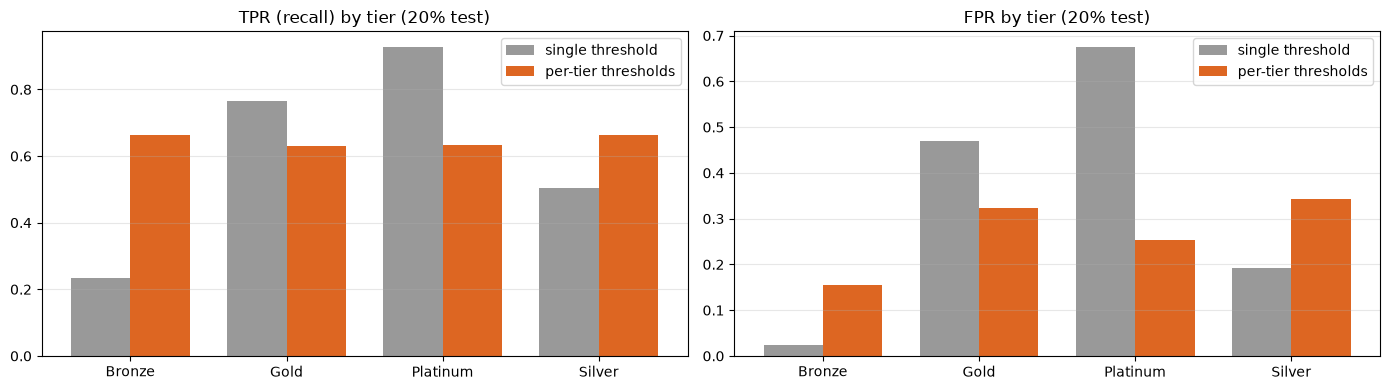

In [18]:
def fit_tier_thresholds(val_proba, global_thr, verbose=True):
    # Per-tier thresholds that give every tier the same validation TPR as the global threshold.
    grid = np.arange(0.01, 0.99, 0.01)
    target_tpr = (val_proba[y_val == 1] >= global_thr).mean()
    thresholds = {}
    for g in sorted(val_groups['customer_tier'].unique()):
        m = (val_groups['customer_tier'] == g).values
        pos_scores = val_proba[m][y_val[m] == 1]
        ok = [t for t in grid if (pos_scores >= t).mean() >= target_tpr]   # highest threshold still reaching the target
        thresholds[g] = round(float(max(ok)) if ok else float(grid[0]), 2)
        if verbose:
            print(f'{g:<9} validation buyers: {len(pos_scores):4d} -> threshold {thresholds[g]:.2f}')
    if verbose:
        print(f'Target TPR (validation, global threshold {global_thr:.2f}): {target_tpr:.3f}')
    return thresholds

tier_thresholds = fit_tier_thresholds(tabnet_val_proba, thr_tabnet)

tier_before = fairness_table(y_test, tabnet_test_proba, test_groups['customer_tier'], thr_tabnet)
tier_after = fairness_table(y_test, tabnet_test_proba, test_groups['customer_tier'], tier_thresholds)
print('\nTest split - BEFORE (single threshold):'); display(tier_before.style.format(FMT))
print('Test split - AFTER (per-tier thresholds):'); display(tier_after.style.format(FMT))

row_thr = test_groups['customer_tier'].map(tier_thresholds).values
pred_global, pred_tier = (tabnet_test_proba >= thr_tabnet).astype(int), (tabnet_test_proba >= row_thr).astype(int)
mitigation_summary = pd.DataFrame({
    'single threshold': {**gaps(tier_before), 'overall F1': f1_score(y_test, pred_global),
                         'overall precision': precision_score(y_test, pred_global), 'overall recall': recall_score(y_test, pred_global),
                         'customers flagged': pred_global.sum()},
    'per-tier thresholds': {**gaps(tier_after), 'overall F1': f1_score(y_test, pred_tier),
                            'overall precision': precision_score(y_test, pred_tier), 'overall recall': recall_score(y_test, pred_tier),
                            'customers flagged': pred_tier.sum()}})
mitigation_summary['change'] = mitigation_summary['per-tier thresholds'] - mitigation_summary['single threshold']
display(mitigation_summary.style.format('{:.3f}'))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(tier_before)); w = 0.38
for a, metric in zip(axes, ['TPR (recall)', 'FPR']):
    a.bar(x - w/2, tier_before[metric], w, label='single threshold', color='#999')
    a.bar(x + w/2, tier_after[metric], w, label='per-tier thresholds', color='#d62')
    a.set_xticks(x); a.set_xticklabels(tier_before.index); a.set_title(f'{metric} by tier (20% test)'); a.legend(); a.grid(alpha=.3, axis='y')
plt.tight_layout(); plt.show()

### 11.7 Mitigation 2: remove `age` from the model (fairness through unawareness)
Age is a personal characteristic. Using it to decide who receives retention offers needs a justification, so we test whether the model actually needs it: retrain the selected TabNet configuration **without `age` and `age_is_missing`** on the same split, then compare accuracy and the age-band audit.

Removing a column is not enough on its own: other features can act as a **proxy** for age. We therefore also measure how well the remaining features can predict age (R² on the test split). Low R² = weak proxies.

In [19]:
AGE_COLS = ['age', 'age_is_missing']
prep_noage = TabNetPreprocessor([c for c in NUMERIC_COLS if c not in AGE_COLS], CATEGORICAL_COLS).fit(labelled.iloc[idx_train])
Xtr_na, Xva_na, Xte_na = (prep_noage.transform(labelled.iloc[i]) for i in (idx_train, idx_val, idx_test))

set_seed(); t0 = time.time()
tabnet_noage = TabNetClassifier(n_d=best_cfg['n_d'], n_a=best_cfg['n_a'], n_steps=best_cfg['n_steps'], gamma=best_cfg['gamma'],
                                lambda_sparse=best_cfg['lambda_sparse'], optimizer_params=dict(lr=best_cfg['lr']),
                                **{**COMMON, 'cat_idxs': prep_noage.cat_idxs_, 'cat_dims': prep_noage.cat_dims_})
tabnet_noage.fit(Xtr_na, y_train, eval_set=[(Xtr_na[trn_mon], y_train[trn_mon]), (Xva_na, y_val)], eval_name=['train', 'val'],
                 weights=best_cfg['weights'], **FIT)
noage_val_proba = tabnet_noage.predict_proba(Xva_na)[:, 1]
noage_test_proba = tabnet_noage.predict_proba(Xte_na)[:, 1]
thr_noage, _ = best_f1_threshold(y_val, noage_val_proba)
print(f'Trained without age in {(time.time()-t0)/60:.1f} min (best epoch {tabnet_noage.best_epoch}), threshold {thr_noage:.2f}')

noage_cmp = pd.DataFrame([evaluate('TabNet with age', y_test, tabnet_test_proba, thr_tabnet),
                          evaluate('TabNet without age', y_test, noage_test_proba, thr_noage)]).set_index('model')
display(noage_cmp[['ROC-AUC', 'PR-AUC', 'F1', 'Precision', 'Recall']].style.format('{:.4f}'))

# Paired bootstrap on the ROC-AUC cost of removing age
rng = np.random.RandomState(SEED); d = []
for _ in range(1000):
    s_ = rng.randint(0, len(y_test), len(y_test))
    d.append(roc_auc_score(y_test[s_], noage_test_proba[s_]) - roc_auc_score(y_test[s_], tabnet_test_proba[s_]))
lo, hi = np.percentile(d, [2.5, 97.5])
print(f'ROC-AUC change from removing age: {np.mean(d):+.4f}, 95% CI [{lo:+.4f}, {hi:+.4f}]'
      f"  -> {'significant' if (lo > 0 or hi < 0) else 'not significant'}")

age_before = fairness_table(y_test, tabnet_test_proba, test_groups['age_band'], thr_tabnet)
age_after = fairness_table(y_test, noage_test_proba, test_groups['age_band'], thr_noage)
print('\nAge-band audit - WITH age:'); display(age_before.style.format(FMT))
print('Age-band audit - WITHOUT age:'); display(age_after.style.format(FMT))
display(pd.DataFrame({'with age': gaps(age_before), 'without age': gaps(age_after)}).style.format('{:.3f}'))

# Proxy check: can the remaining features reconstruct age?
known = labelled['age'].notna().values
tr_m, te_m = known[idx_train], known[idx_test]
proxy_feats = [c for c in FEATURE_COLS if c not in AGE_COLS]
proxy = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=SEED, verbose=-1).fit(
    X_lgb.iloc[idx_train][proxy_feats][tr_m], labelled['age'].values[idx_train][tr_m])
from sklearn.metrics import r2_score
r2 = r2_score(labelled['age'].values[idx_test][te_m], proxy.predict(X_lgb.iloc[idx_test][proxy_feats][te_m]))
print(f'\nProxy check - R^2 of predicting age from the other features (test split): {r2:.3f}')
print('Interpretation:', 'weak proxies - removing age genuinely removes age information' if r2 < 0.1
      else 'other features partly encode age - removing the column alone is not sufficient')


Early stopping occurred at epoch 27 with best_epoch = 15 and best_val_auc = 0.87025
Trained without age in 1.3 min (best epoch 15), threshold 0.30


,ROC-AUC,PR-AUC,F1,Precision,Recall
model,,,,,
TabNet with age,0.8736,0.5681,0.5412,0.4719,0.6343
TabNet without age,0.8735,0.5672,0.5406,0.4849,0.6107


ROC-AUC change from removing age: -0.0002, 95% CI [-0.0027, +0.0024]  -> not significant

Age-band audit - WITH age:


,n,threshold,actual buy rate,flagged rate,TPR (recall),FPR,precision
group,,,,,,,
18-24,"1,769",0.25,18.3%,25.8%,0.728,0.154,0.514
25-34,"2,959",0.25,16.6%,23.2%,0.675,0.144,0.483
35-49,"5,072",0.25,13.7%,17.9%,0.608,0.111,0.465
50-64,"2,087",0.25,11.1%,14.7%,0.543,0.097,0.412
65+,273,0.25,11.4%,10.6%,0.419,0.066,0.448
unknown,640,0.25,14.5%,18.9%,0.591,0.121,0.455


Age-band audit - WITHOUT age:


,n,threshold,actual buy rate,flagged rate,TPR (recall),FPR,precision
group,,,,,,,
18-24,"1,769",0.30,18.3%,24.6%,0.721,0.140,0.534
25-34,"2,959",0.30,16.6%,21.0%,0.638,0.124,0.506
35-49,"5,072",0.30,13.7%,17.2%,0.586,0.106,0.467
50-64,"2,087",0.30,11.1%,13.8%,0.517,0.091,0.417
65+,273,0.30,11.4%,10.3%,0.419,0.062,0.464
unknown,640,0.30,14.5%,16.6%,0.559,0.099,0.491


,with age,without age
TPR gap,0.308,0.302
FPR gap,0.087,0.078
precision gap,0.102,0.118
max |flagged - actual|,0.076,0.064



Proxy check - R^2 of predicting age from the other features (test split): 0.007
Interpretation: weak proxies - removing age genuinely removes age information


In [20]:
print('=' * 72); print('BIAS MITIGATION SUMMARY'); print('=' * 72)
mb, ma = mitigation_summary['single threshold'], mitigation_summary['per-tier thresholds']
print(f"Per-tier thresholds {tier_thresholds}")
print(f"  tier TPR gap  {mb['TPR gap']:.3f} -> {ma['TPR gap']:.3f} | FPR gap {mb['FPR gap']:.3f} -> {ma['FPR gap']:.3f}")
print(f"  overall F1    {mb['overall F1']:.4f} -> {ma['overall F1']:.4f}")
print(f"Removing age: ROC-AUC {noage_cmp.iloc[0]['ROC-AUC']:.4f} -> {noage_cmp.iloc[1]['ROC-AUC']:.4f} "
      f"| age-band TPR gap {gaps(age_before)['TPR gap']:.3f} -> {gaps(age_after)['TPR gap']:.3f} | proxy R^2 {r2:.3f}")
pd.concat({'tier_single': tier_before, 'tier_per_tier': tier_after, 'age_with': age_before, 'age_without': age_after}
          ).to_csv('outputs/bias_mitigation_test.csv')

BIAS MITIGATION SUMMARY
Per-tier thresholds {'Bronze': 0.1, 'Gold': 0.32, 'Platinum': 0.58, 'Silver': 0.19}
  tier TPR gap  0.694 -> 0.033 | FPR gap 0.652 -> 0.189
  overall F1    0.5412 -> 0.4550
Removing age: ROC-AUC 0.8736 -> 0.8735 | age-band TPR gap 0.308 -> 0.302 | proxy R^2 0.007


### 11.8 Interpretation of the bias audit and mitigations

**Country - no action needed.** TPR differs by at most 0.07, FPR by 0.02, and flagged rates (19-22%) track actual buy rates in every market.

**Loyalty tier - severe bias with a single threshold, largely fixed by per-tier thresholds.**
* With one threshold (0.25), only **23%** of Bronze buyers are flagged versus **93%** of Platinum buyers (TPR gap 0.69). Platinum is over-flagged (81% flagged vs 53% who actually bought) and Bronze under-flagged (3.5% vs 5.3%).
* Per-tier thresholds (Bronze 0.10, Silver 0.19, Gold 0.32, Platinum 0.58), chosen on validation, cut the **TPR gap from 0.69 to 0.03** and the **FPR gap from 0.65 to 0.19** on the untouched test split.
* **Cost:** overall F1 drops from 0.541 to 0.455 and precision from 0.47 to 0.35, because 925 more customers are flagged (mostly low-base-rate Bronze customers). The **precision gap widens** (0.25 -> 0.55). This is the known impossibility result (Kleinberg et al., 2016; Chouldechova, 2017): when base rates differ, equal opportunity and predictive parity cannot both hold. Which criterion matters is a **business decision**: if being on the list means getting a benefit (an offer), equal opportunity is the right target and the precision loss is the price of fair access.
* The thresholds are based on 154-227 validation buyers per tier, so they carry sampling noise and should be re-checked on a later cut-off.

**Age - the `age` column can be removed at no cost.**
* Removing `age` and `age_is_missing` changes test ROC-AUC by **-0.0002** (95% CI [-0.0027, +0.0024], not significant).
* The remaining features predict age with **R² = 0.007**, so there are no strong proxies: dropping the column really removes age information.
* The age-band TPR gap (0.31, mainly the small 65+ group, n = 273) is **almost unchanged** without age (0.30). It comes from real behavioural differences (younger customers browse and buy more: 18% vs 11% buy rate), not from the model using age directly. Per-group thresholds by age are *not* recommended: that would make age an explicit input to the decision.

**Recommendation for the prototype.** Deploy the model **without `age`** (same accuracy, less personal data, which supports data minimisation). Use **per-tier thresholds** for the win-back list, and show staff the raw probability next to the yes/no flag. Keep a human approval step (W9), and repeat this audit each time the model is retrained.

### 11.9 Final deployed model: TabNet without `age` + per-tier thresholds
Following 11.8, the model used by the prototype/agent is the **TabNet retrained without `age`/`age_is_missing`** (same architecture and hyper-parameters), with **per-tier decision thresholds re-fitted on the validation split for this model**. The head-to-head comparison with LightGBM in Section 11 stays on the full 47 features so that both models see identical inputs.

In [21]:
FINAL_MODEL, FINAL_PREP, FINAL_THR = tabnet_noage, prep_noage, thr_noage
FINAL_FEATURES = [c for c in FEATURE_COLS if c not in AGE_COLS]
final_val_proba, final_test_proba, X_test_final = noage_val_proba, noage_test_proba, Xte_na
final_tier_thresholds = fit_tier_thresholds(final_val_proba, FINAL_THR)

final_row_thr = test_groups['customer_tier'].map(final_tier_thresholds).values
final_pred = (final_test_proba >= final_row_thr).astype(int)
final_tier_tab = fairness_table(y_test, final_test_proba, test_groups['customer_tier'], final_tier_thresholds)
print('Deployed model - tier audit on the 20% test split:'); display(final_tier_tab.style.format(FMT))

deployed = pd.DataFrame({
    'TabNet with age, single threshold (Section 11)': {
        'ROC-AUC': roc_auc_score(y_test, tabnet_test_proba), 'PR-AUC': average_precision_score(y_test, tabnet_test_proba),
        'F1': f1_score(y_test, pred_global), 'Precision': precision_score(y_test, pred_global),
        'Recall': recall_score(y_test, pred_global), **gaps(tier_before)},
    'Deployed: TabNet without age, per-tier thresholds': {
        'ROC-AUC': roc_auc_score(y_test, final_test_proba), 'PR-AUC': average_precision_score(y_test, final_test_proba),
        'F1': f1_score(y_test, final_pred), 'Precision': precision_score(y_test, final_pred),
        'Recall': recall_score(y_test, final_pred), **gaps(final_tier_tab)}}).T
deployed.to_csv('outputs/deployed_model_test.csv')
display(deployed.style.format('{:.4f}'))

Bronze    validation buyers:  183 -> threshold 0.12
Gold      validation buyers:  182 -> threshold 0.37
Platinum  validation buyers:  227 -> threshold 0.57
Silver    validation buyers:  154 -> threshold 0.23
Target TPR (validation, global threshold 0.30): 0.592
Deployed model - tier audit on the 20% test split:


,n,threshold,actual buy rate,flagged rate,TPR (recall),FPR,precision
group,,,,,,,
Bronze,"8,166",0.12,5.3%,19.3%,0.674,0.166,0.186
Gold,"1,374",0.37,29.8%,36.7%,0.567,0.282,0.460
Platinum,"1,125",0.57,53.2%,44.8%,0.617,0.256,0.732
Silver,"2,135",0.23,19.8%,39.3%,0.668,0.325,0.336


,ROC-AUC,PR-AUC,F1,Precision,Recall,TPR gap,FPR gap,precision gap,max |flagged - actual|
"TabNet with age, single threshold (Section 11)",0.8736,0.5681,0.5412,0.4719,0.6343,0.6941,0.6518,0.2513,0.2782
"Deployed: TabNet without age, per-tier thresholds",0.8735,0.5672,0.4449,0.3435,0.6311,0.1071,0.1589,0.5459,0.1953


## 12. Explainability (W2): global and per-customer feature attention
Shown for the **deployed model** (without `age`). TabNet's `feature_importances_` aggregate the attention masks over all decision steps (global view). `explain()` returns the mask for **each individual customer**, i.e. which inputs the network actually used for that prediction - the basis for telling a CRM executive *why* a customer is scored high or low.

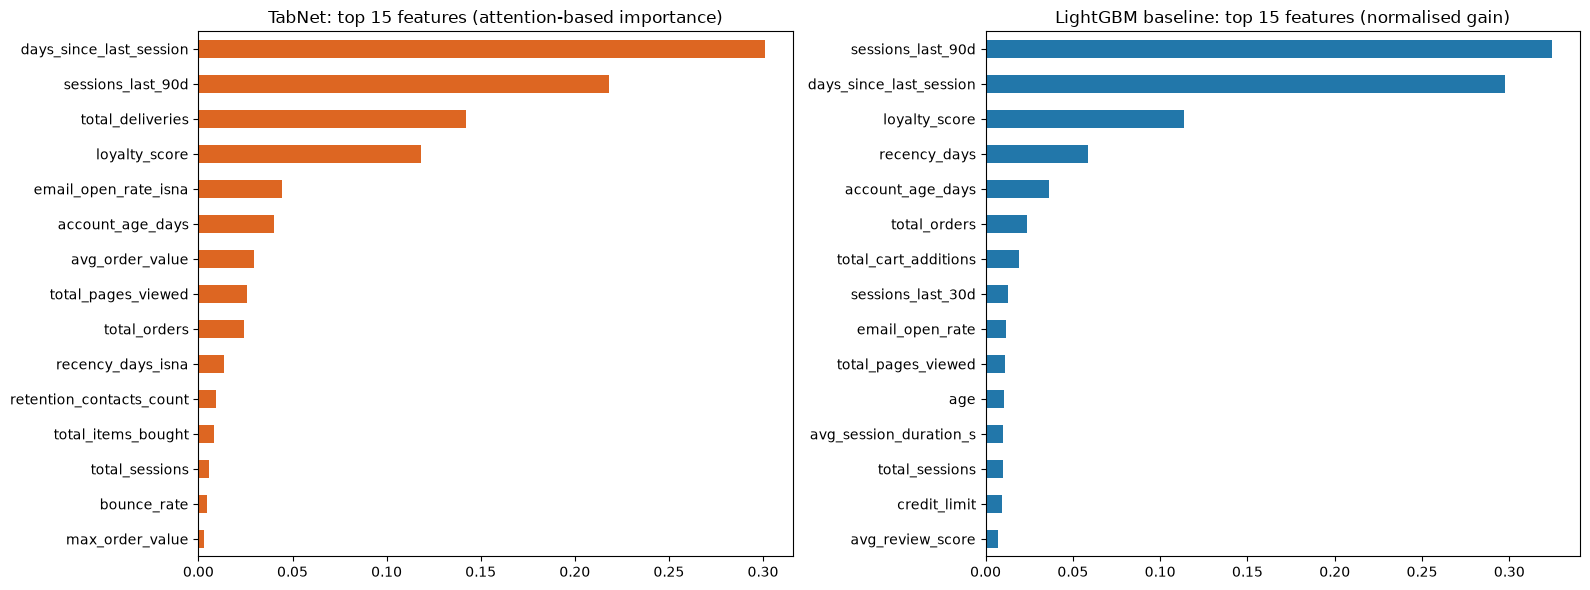

In [22]:
imp = pd.Series(FINAL_MODEL.feature_importances_, index=FINAL_PREP.columns_).sort_values(ascending=False)
lgb_imp = pd.Series(lgb_model.feature_importance('gain'), index=FEATURE_COLS)
lgb_imp = lgb_imp / lgb_imp.sum()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
imp.head(15)[::-1].plot.barh(ax=axes[0], color='#d62'); axes[0].set_title('TabNet: top 15 features (attention-based importance)')
lgb_imp.sort_values(ascending=False).head(15)[::-1].plot.barh(ax=axes[1], color='#27a'); axes[1].set_title('LightGBM baseline: top 15 features (normalised gain)')
plt.tight_layout(); plt.show()
imp.to_csv('outputs/tabnet_feature_importance.csv', header=['importance'])

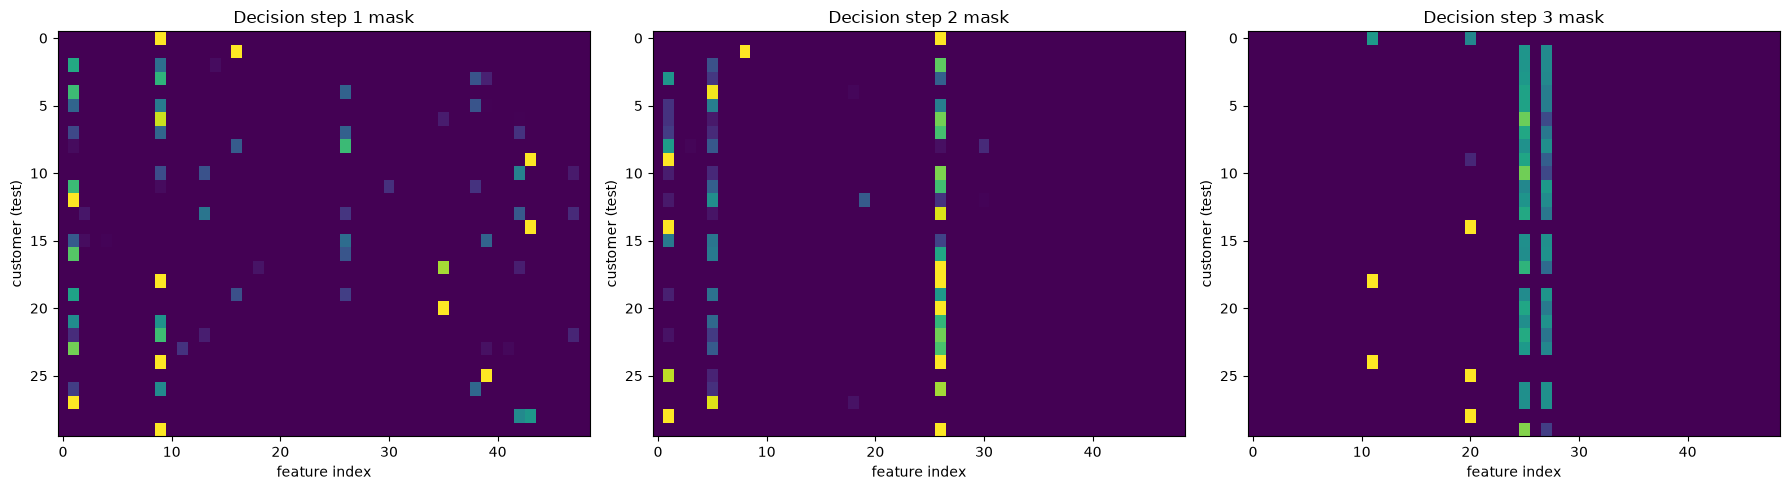

Customer 9992: P(purchase in Oct) = 99.7% | actual = 1
   sessions_last_90d            attention 47.7%   value = 61
   total_deliveries             attention 43.9%   value = 156
   orders_last_30d              attention 4.7%   value = 5
   do_not_contact               attention 3.7%   value = 0
   credit_limit                 attention 0.0%   value = 10005.0

Customer 6563: P(purchase in Oct) = 0.0% | actual = 0
   days_since_last_session      attention 72.8%   value = 762.0
   sessions_last_90d            attention 11.5%   value = 0
   email_open_rate_isna         attention 5.5%   value = False
   total_deliveries             attention 4.8%   value = 2
   max_order_value              attention 3.9%   value = 274.47


In [23]:
explain_matrix, step_masks = FINAL_MODEL.explain(X_test_final)
explain_df = pd.DataFrame(explain_matrix, columns=FINAL_PREP.columns_)
explain_df = explain_df.div(explain_df.sum(axis=1), axis=0)

# Attention mask of each decision step for the first 30 test customers
fig, axes = plt.subplots(1, len(step_masks), figsize=(6 * len(step_masks), 5))
for s, a in enumerate(np.atleast_1d(axes)):
    a.imshow(step_masks[s][:30], aspect='auto', cmap='viridis'); a.set_title(f'Decision step {s+1} mask')
    a.set_xlabel('feature index'); a.set_ylabel('customer (test)')
plt.tight_layout(); plt.show()

def explain_customer(row_pos, top_n=5):
    # Top features the network attended to for one test-split customer.
    cid = int(labelled.iloc[idx_test[row_pos]]['customer_id'])
    top = explain_df.iloc[row_pos].sort_values(ascending=False).head(top_n)
    raw = labelled.iloc[idx_test[row_pos]]
    print(f'Customer {cid}: P(purchase in Oct) = {final_test_proba[row_pos]:.1%} | actual = {y_test[row_pos]}')
    for f, w in top.items():
        value = pd.isna(raw[f[:-5]]) if f.endswith('_isna') else raw[f]
        print(f'   {f:<28} attention {w:.1%}   value = {value}')

explain_customer(int(np.argmax(final_test_proba)))
print()
explain_customer(int(np.argmin(final_test_proba)))

## 13. Save the model and preprocessing artefacts
The agent / dashboard needs: the trained network (the **deployed model without `age`**), the fitted preprocessor (so new customers are transformed exactly as in training), the column order, the global threshold and the per-tier thresholds.

In [24]:
model_path = FINAL_MODEL.save_model('models/tabnet_repurchase')     # -> models/tabnet_repurchase.zip
joblib.dump({'preprocessor': FINAL_PREP, 'feature_cols': FINAL_FEATURES, 'categorical_cols': CATEGORICAL_COLS,
             'dropped_features': AGE_COLS, 'threshold': FINAL_THR, 'tier_thresholds': final_tier_thresholds,
             'best_config': best_cfg, 'used_pretraining': False, 'cutoff_date': CUTOFF}, 'models/tabnet_artifacts.joblib')
lgb_model.save_model('models/lightgbm_baseline_8020.txt', num_iteration=lgb_model.best_iteration)

# Verify the saved model reloads and reproduces the predictions exactly
reloaded = TabNetClassifier(); reloaded.load_model(model_path)
assert np.allclose(reloaded.predict_proba(X_test_final)[:, 1], final_test_proba, atol=1e-6)
# Verify the artefacts load in a fresh process (as the agent would load them)
import subprocess, sys
check = subprocess.run([sys.executable, '-c', "import joblib; from tabnet_preprocessing import TabNetPreprocessor; "
                        "a = joblib.load('models/tabnet_artifacts.joblib'); print(len(a['preprocessor'].columns_), a['tier_thresholds'])"],
                       capture_output=True, text=True)
assert check.returncode == 0, check.stderr
print('Fresh-process load OK:', check.stdout.strip())
print('Saved and verified:', model_path, '| models/tabnet_artifacts.joblib | models/lightgbm_baseline_8020.txt')

Successfully saved model at models/tabnet_repurchase.zip
Fresh-process load OK: 49 {'Bronze': 0.12, 'Gold': 0.37, 'Platinum': 0.57, 'Silver': 0.23}
Saved and verified: models/tabnet_repurchase.zip | models/tabnet_artifacts.joblib | models/lightgbm_baseline_8020.txt


## 14. Predictions for `test.csv` (unlabelled customers) and a scoring helper
Both files come from the deployed model. `submission_tabnet_label.csv` uses the single F1-optimal threshold, so it is comparable with the LightGBM submission. The per-tier thresholds are applied in `score_customer()`, which is what the win-back list and the agent use.

In [25]:
unlab_proba = FINAL_MODEL.predict_proba(FINAL_PREP.transform(unlabelled))[:, 1]
pd.DataFrame({'customer_id': unlabelled['customer_id'].astype(int), 'target': unlab_proba}).to_csv('submission_tabnet_prob.csv', index=False)
pd.DataFrame({'customer_id': unlabelled['customer_id'].astype(int), 'target': (unlab_proba >= FINAL_THR).astype(int)}).to_csv('submission_tabnet_label.csv', index=False)
print(f'submission_tabnet_prob.csv / submission_tabnet_label.csv written | predicted purchase rate {(unlab_proba >= FINAL_THR).mean():.2%}')

def score_customer(customer_id, model=FINAL_MODEL, preprocessor=FINAL_PREP, threshold=FINAL_THR, tier_thr=final_tier_thresholds):
    # Score one customer with the trained TabNet - this is the function the agent will call as a tool.
    # The yes/no decision uses the customer's tier threshold (bias mitigation, Section 11.6).
    row = df[df['customer_id'] == customer_id]
    if row.empty:
        return {'customer_id': customer_id, 'error': 'not found'}
    x = preprocessor.transform(row)
    proba = float(model.predict_proba(x)[0, 1])
    attn, _ = model.explain(x)
    attn = pd.Series(attn[0], index=preprocessor.columns_); attn = attn / attn.sum()
    tier = str(row['customer_tier'].iloc[0]); t = tier_thr.get(tier, threshold)
    return {'customer_id': int(customer_id), 'customer_tier': tier, 'purchase_probability': round(proba, 4),
            'predicted_purchase': bool(proba >= t), 'threshold_used': t, 'global_threshold': round(threshold, 2),
            'top_drivers': {k: round(float(v), 3) for k, v in attn.sort_values(ascending=False).head(5).items()}}

score_customer(10126)

submission_tabnet_prob.csv / submission_tabnet_label.csv written | predicted purchase rate 17.64%


{'customer_id': 10126,
 'customer_tier': 'Silver',
 'purchase_probability': 0.0234,
 'predicted_purchase': False,
 'threshold_used': 0.23,
 'global_threshold': 0.3,
 'top_drivers': {'sessions_last_90d': 0.364,
  'days_since_last_session': 0.347,
  'total_deliveries': 0.197,
  'total_items_bought': 0.058,
  'loyalty_score': 0.023}}

## 15. Summary and interpretation

In [26]:
t, l = comparison.loc['TabNet (deep learning)'], comparison.loc['LightGBM (baseline)']
print('=' * 72)
print('FINAL RESULTS ON THE 20% HOLD-OUT TEST SET (12,800 customers)')
print('=' * 72)
print(f"{'metric':<12}{'TabNet':>12}{'LightGBM':>12}{'diff':>12}")
for m in ['ROC-AUC', 'PR-AUC', 'F1', 'Precision', 'Recall', 'Accuracy']:
    print(f'{m:<12}{t[m]:>12.4f}{l[m]:>12.4f}{t[m]-l[m]:>+12.4f}')
print(f"\nSelected TabNet config: {best_cfg} | pre-training used: {USE_PRETRAINING}")
d = deployed.iloc[1]
print(f"\nDEPLOYED MODEL (no age, per-tier thresholds {final_tier_thresholds}):")
print(f"  ROC-AUC {d['ROC-AUC']:.4f} | PR-AUC {d['PR-AUC']:.4f} | F1 {d['F1']:.4f} | tier TPR gap {d['TPR gap']:.3f}")

FINAL RESULTS ON THE 20% HOLD-OUT TEST SET (12,800 customers)
metric            TabNet    LightGBM        diff
ROC-AUC           0.8736      0.8756     -0.0019
PR-AUC            0.5681      0.5706     -0.0025
F1                0.5412      0.5430     -0.0019
Precision         0.4719      0.4967     -0.0248
Recall            0.6343      0.5989     +0.0354
Accuracy          0.8433      0.8531     -0.0098

Selected TabNet config: {'n_d': 8, 'n_a': 8, 'n_steps': 3, 'gamma': 1.3, 'lambda_sparse': 0.001, 'lr': 0.02, 'weights': 0} | pre-training used: False

DEPLOYED MODEL (no age, per-tier thresholds {'Bronze': 0.12, 'Gold': 0.37, 'Platinum': 0.57, 'Silver': 0.23}):
  ROC-AUC 0.8735 | PR-AUC 0.5672 | F1 0.4449 | tier TPR gap 0.107


**How to read these results**
* **ROC-AUC** is the probability that a randomly chosen buyer is ranked above a randomly chosen non-buyer. This is the most relevant metric for producing a ranked win-back list.
* **PR-AUC** focuses on the minority (buyer) class; the no-skill level equals the positive rate (~0.146).
* **Accuracy** is reported for completeness but is not a useful success measure here: the majority-class rule already gets ~85%.
* The paired bootstrap (11.1) shows whether any gap between TabNet and LightGBM is larger than the noise from the particular 20% sample.

**Discussion points**
* On medium-sized tabular data, gradient-boosted trees are a very strong baseline and deep tabular models typically match rather than beat them (Grinsztajn et al., 2022; Shwartz-Ziv & Armon, 2022). The value of TabNet in this project is (a) meeting the deep-learning requirement with a model that is competitive with the baseline, and (b) built-in, per-customer attention explanations for W2 and the agent.
* Both models agree on the dominant drivers: recent browsing activity (`days_since_last_session`, `sessions_last_90d`), `loyalty_score` and purchase recency. Purchase intent is mostly visible in **recent engagement**.
* **Bias:** Sections 11.5-11.9 audit fairness and apply two mitigations. The **deployed model** drops `age` and uses per-tier thresholds; the comparison table above is the like-for-like TabNet vs LightGBM benchmark on all 47 features.
* **Limitations / what we would not yet trust in production:** single 80/20 split and single seed (scores vary by roughly +/-0.005 AUC between seeds); predictions are correlational, so a high score does not mean a voucher will *cause* a purchase (W10 needs uplift / A-B evaluation); the model is trained on one cut-off date, so it should be re-validated on a later cut-off before use.
* **Next steps:** seed ensembling of TabNet, additional features from unused tables (product categories from `transaction_items`, campaign exposure from `sessions.campaign_id`, regional data from `geo_data`), and an ensemble of TabNet + LightGBM.